# CogLab — Stroop Experiment Analysis

This notebook presents a reproducible analysis of behavioral data generated by
the CogLab Stroop experiment.

The workflow covers:

- trial-level data inspection
- dataset validation
- congruent and incongruent conditions
- response accuracy
- reaction-time statistics
- Stroop effect
- behavioral visualizations
- interpretation of the sample session

The analysis is descriptive and uses a single sample session. It is intended
to demonstrate the experimental and data-analysis workflow rather than make
population-level statistical claims.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
Path.cwd()

PosixPath('/Users/mercan/coglab/analysis')

## 1. Dataset Loading and Inspection

The Stroop experiment exports trial-level behavioral data as CSV.

This section loads the sample session and inspects its basic structure before
performing any statistical analysis.

In [3]:
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "sample" / "stroop_session_sample.csv"

print(DATA_PATH)
print("File exists:", DATA_PATH.exists())

/Users/mercan/coglab/data/sample/stroop_session_sample.csv
File exists: True


In [4]:
df = pd.read_csv(DATA_PATH)

df.head()

,trial,word,inkColor,condition,response,correct,reactionTime
0,1,GREEN,blue,incongruent,blue,True,1008
1,2,BLUE,blue,congruent,blue,True,573
2,3,RED,red,congruent,red,True,558
3,4,BLUE,red,incongruent,red,True,437
4,5,BLUE,blue,congruent,blue,True,608


## 2. Dataset Validation

Before analyzing the Stroop effect, the dataset is checked for the expected
columns, number of trials, missing values, and experimental conditions.

The experimental session is expected to contain:

- 24 recorded trials
- 12 congruent trials
- 12 incongruent trials
- no missing required columns

In [5]:
required_columns = {
    "trial",
    "word",
    "inkColor",
    "condition",
    "response",
    "correct",
    "reactionTime",
}

missing_columns = required_columns - set(df.columns)

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isna().sum())

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

if len(df) != 24:
    raise ValueError(
        f"Expected 24 experimental trials, found {len(df)}"
    )

valid_conditions = {"congruent", "incongruent"}

unexpected_conditions = (
    set(df["condition"].unique()) - valid_conditions
)

if unexpected_conditions:
    raise ValueError(
        f"Unexpected conditions found: {unexpected_conditions}"
    )

condition_counts = df["condition"].value_counts()

if condition_counts.get("congruent", 0) != 12:
    raise ValueError("Expected 12 congruent trials.")

if condition_counts.get("incongruent", 0) != 12:
    raise ValueError("Expected 12 incongruent trials.")

print("\nValidation passed.")
print(condition_counts)

Dataset shape: (24, 7)

Missing values:
trial           0
word            0
inkColor        0
condition       0
response        0
correct         0
reactionTime    0
dtype: int64

Validation passed.
condition
incongruent    12
congruent      12
Name: count, dtype: int64


## 3. Response Accuracy by Condition

Response accuracy is calculated separately for congruent and incongruent trials.

Accuracy represents the percentage of trials in which the participant selected
the correct ink color.

In [6]:
accuracy_by_condition = (
    df.groupby("condition")["correct"].mean() * 100
)

accuracy_by_condition

condition
congruent      100.000000
incongruent     91.666667
Name: correct, dtype: float64

## 4. Reaction-Time Statistics and Stroop Effect

Reaction-time statistics are calculated using only correct responses.

For each experimental condition, the analysis reports:

- number of correct trials
- mean reaction time
- median reaction time
- sample standard deviation

The Stroop effect is defined as:

**Mean RT (Incongruent) - Mean RT (Congruent)**

A positive value indicates slower responses during incongruent trials in this
sample session.

In [7]:
correct_trials = df[df["correct"]].copy()

rt_stats = (
    correct_trials
    .groupby("condition")["reactionTime"]
    .agg(["count", "mean", "median", "std"])
    .reindex(["congruent", "incongruent"])
)

stroop_effect = (
    rt_stats.loc["incongruent", "mean"]
    - rt_stats.loc["congruent", "mean"]
)

print("Reaction-time statistics for correct responses:")
display(rt_stats.round(2))

print(f"Stroop effect: {stroop_effect:.2f} ms")

Reaction-time statistics for correct responses:


,count,mean,median,std
condition,,,,
congruent,12,539.00,556.0,71.48
incongruent,11,653.91,599.0,201.73


Stroop effect: 114.91 ms


## 5. Behavioral Visualizations

The descriptive results are visualized to make the difference between
congruent and incongruent conditions easier to interpret.

Two measures are presented:

- mean reaction time for correct responses
- response accuracy by condition

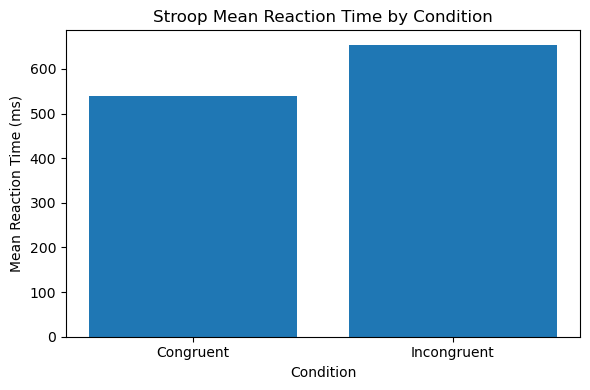

In [8]:
FIGURE_DIR = Path.cwd() / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

condition_order = ["congruent", "incongruent"]

mean_rt_values = rt_stats.loc[condition_order, "mean"]

plt.figure(figsize=(6, 4))

plt.bar(
    ["Congruent", "Incongruent"],
    mean_rt_values,
)

plt.ylabel("Mean Reaction Time (ms)")
plt.xlabel("Condition")
plt.title("Stroop Mean Reaction Time by Condition")

plt.tight_layout()

rt_figure_path = FIGURE_DIR / "stroop_mean_rt.png"
plt.savefig(rt_figure_path, dpi=150)

plt.show()

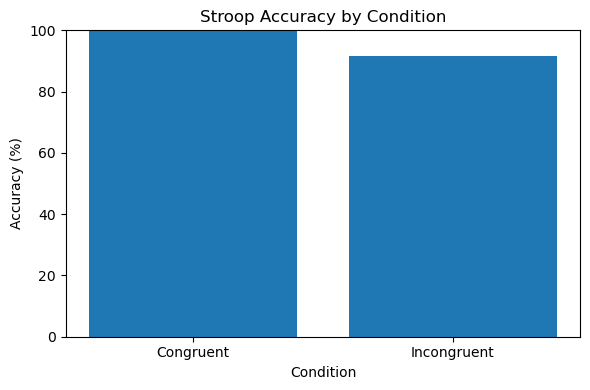

In [9]:
accuracy_values = accuracy_by_condition.loc[condition_order]

plt.figure(figsize=(6, 4))

plt.bar(
    ["Congruent", "Incongruent"],
    accuracy_values,
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Condition")
plt.title("Stroop Accuracy by Condition")
plt.ylim(0, 100)

plt.tight_layout()

accuracy_figure_path = FIGURE_DIR / "stroop_accuracy.png"
plt.savefig(accuracy_figure_path, dpi=150)

plt.show()

## 6. Interpretation and Conclusion

In this sample session, performance differed between the congruent and
incongruent Stroop conditions.

### Reaction Time

Mean reaction time for correct responses was:

- **Congruent:** 539.00 ms
- **Incongruent:** 653.91 ms

The resulting Stroop effect was:

**653.91 - 539.00 = 114.91 ms**

Thus, correct responses were approximately **115 ms slower** in the
incongruent condition in this sample session.

### Accuracy

Response accuracy was:

- **Congruent:** 100%
- **Incongruent:** 91.67%

The incongruent condition therefore showed both slower responses and slightly
lower accuracy in this session.

### Interpretation

This pattern is descriptively consistent with the Stroop interference effect:
when the meaning of a color word conflicts with its displayed ink color,
response selection can require additional cognitive control.

However, this notebook analyzes only a single sample session. The results
should therefore be interpreted as a demonstration of the experimental and
data-analysis workflow rather than as evidence about a population.

Future analyses could include multiple participants, inferential statistical
tests, effect-size estimates, confidence intervals, and participant-level
visualizations.